# MTI850 - Livrable partiel 1 : Compréhension et préparation des données

In [1]:
# -------------------------------------------------------------
# BIXI — BIG DATA ANALYTICS
# -------------------------------------------------------------
# Team
# Student Names: Fortin Laurine, Beaugeois Carole, Elfassi Ethan
# Dataset: https://bixi.com/en/open-data/
# Date: 20 nov. 2026
# -------------------------------------------------------------

## 1. Présentation du problème et description des données

### 1.1 Énoncé du problème
Prédire la demande horaire (nombre de départs et d'arrivées) par station du réseau BIXI à Montréal en tenant compte des conditions météorologiques (notamment les précipitations) et anticiper les périodes de surplus ou de pénurie probables. L'objectif est de comparer l'utilisation du service selon la pluie et de permettre un rééquilibrage proactif des vélos afin d'améliorer leur disponibilité pour les usagers tout en réduisant les coûts logistiques et l'empreinte carbone des opérations de redistribution.

### 1.2 Pertinence pour le Big Data

Ce problème relève du Big Data en raison du volume important d'historiques de trajets (plusieurs dizaines de millions de trajets sur plusieurs années, soit plusieurs gigaoctets de données ; le fichier de l'année 2026 seul compte ~9,5 millions de lignes pour ~1,86 Go), de la variété / hétérogénéité des sources à croiser (historique des trajets BIXI, métadonnées géographiques des stations, relevés événementiels de pluviométrie issus de 50 capteurs municipaux et calendrier), ainsi que du besoin de traitement distribué (Spark / HDFS) pour le nettoyage, la jointure spatio-temporelle à l'heure près, le calcul de variables décalées et la simulation en continu.

### 1.3 Description de l'ensemble des données 

  - **Nom et sources :**  
    - Historique des trajets BIXI — [BIXI Open Data](https://bixi.com/en/open-data/).  
    - Données ouvertes de mobilité et de pluviométrie de la Ville de Montréal — [Portail des données ouvertes de Montréal](https://donnees.montreal.ca/).
  - **Type et taille :** Données structurées tabulaires au format CSV :
    - `bixi_trips_2026.csv` : ~1,86 Go (9 504 051 trajets en 2026 ; le jeu multi-années complet dépasse 30–40M de trajets).
    - `pluviometrie_25-27.csv` : ~15,2 Mo (447 334 relevés d'impulsions pluviométriques sur 50 stations `NO_SICOS`, couvrant du 1er janvier 2025 au 28 juin 2026, dont 295 788 relevés en 2026).
  - **Variables clés :**  
    - **Trajets BIXI :** Stations de départ et d'arrivée (`STARTSTATIONNAME`, `ENDSTATIONNAME`), arrondissements (`STARTSTATIONARRONDISSEMENT`, `ENDSTATIONARRONDISSEMENT`), coordonnées GPS (`LATITUDE`, `LONGITUDE`) et horodatages en millisecondes (`STARTTIMEMS`, `ENDTIMEMS`), permettant de dériver la durée (`duration_sec`) et les attributs temporels (`hour`, `day_of_week`, `month`, `is_weekend`).  
    - **Pluviométrie :** Identifiant du pluviomètre (`NO_SICOS`), horodatage (`DATE`), impulsion d'auget (`IMPULSION`, 1 impulsion = 0,2 mm de pluie) et code de validité (`STATUT = 0`), agrégés à l'heure pour obtenir la hauteur de pluie moyenne (`rain_mm`) et l'indicateur de pluie (`is_raining`).
  - **Colonne(s) cible(s) :**  
    Après agrégation horaire par station et jointure avec la pluviométrie, les cibles de régression sont le nombre de départs horaires (`departures`), le nombre d'arrivées horaires (`arrivals`) et le flux net (`net_flow = arrivals - departures`), indicateur direct des surplus ou pénuries à rééquilibrer.
  - **Accès aux données (téléchargement) :**  
    Les fichiers CSV utilisés dans ce notebook (`bixi_trips_2026.csv` et `pluviometrie_25-27.csv`) sont accessibles ici : 
    - [Données BIXI](https://cdn.bixi.com/wp-content/uploads/2026/02/DonneesOuvertes2026_0102030405060708.zip?_gl=1*5if0k4*_gcl_au*Mzk5ODA3NjAwLjE3OTQ5NTI0NzI.*_ga*MjQ2MjgyOTUwLjE3OTQ5NTI0NzI.*_ga_5DRPF9PX4V*czE3OTUyMDIwODgkbzMkZzEkdDE3OTUyMDIwODgkajYwJGwwJGgw)
    - [Données Pluviométrie](https://donnees.montreal.ca/dataset/57e5248f-bd91-4381-af6e-57747158895e/resource/573d6d63-1407-40b3-a2b9-78ff8b9217ef/download/pluviometrie-quantite_2025-2027.csv)
  - **Note sur le périmètre :**  
    Les données de pluviométrie couvrent la période du 1er janvier 2025 au 28 juin 2026 et les trajets BIXI couvrent 2026 (jusqu'au 31 août). L'enrichissement éventuel avec la température, les jours fériés et la capacité des stations sera intégré si nécessaire lors de la phase de modélisation.

## 2. Ingestion des données

Dans cette section, nous configurons l'environnement PySpark, définissons les chemins d'accès locaux et HDFS ainsi que le paramètre d'échantillonnage (`SAMPLE_FRACTION`), puis chargeons les deux sources de données brutes (trajets BIXI et pluviométrie).

In [2]:
import os
import findspark
findspark.init("/opt/spark")

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import StructType, StructField, StringType, DoubleType, LongType
from pyspark.sql.window import Window
from pyspark.ml.feature import StringIndexer, VectorAssembler
import matplotlib.pyplot as plt
import seaborn as sns

# Mettre 1.0 pour toutes les données
SAMPLE_FRACTION = 1.0

TRIPS_PATH = "data/bixi_trips_2026.csv"
RAIN_PATH = "data/pluviometrie_25-27.csv"
OUTPUT_PARQUET_PATH = "df_features.parquet"
HDFS_RAW_PATH = "hdfs://localhost:9000/user/mti850/bixi/raw_trips"
HDFS_RAIN_RAW_PATH = "hdfs://localhost:9000/user/mti850/bixi/raw_rain"
HDFS_OUTPUT_PARQUET_PATH = "hdfs://localhost:9000/user/mti850/bixi/df_features.parquet"

### 2.1 Démarrage de la session Spark

Nous initialisons une session Apache Spark en mode local multi-cœurs (`local[*]`) avec 4 Go de mémoire allouée au driver, un nombre de partitions de *shuffle* réduit à 32 (adapté à l'exécution locale) et l'optimisation adaptative des requêtes (`AQE`) activée.

In [3]:
spark = SparkSession.builder \
    .master("local[*]") \
    .appName("MTI850 - BIXI Montreal - Livrable 1") \
    .config("spark.driver.memory", "4g") \
    .config("spark.sql.shuffle.partitions", "32") \
    .config("spark.sql.adaptive.enabled", "true") \
    .getOrCreate()

spark.sparkContext.setLogLevel("WARN")
print(f"Spark version: {spark.version}")

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/20 15:00:50 WARN Utils: Your hostname, mti850-VirtualBox, resolves to a loopback address: 127.0.1.1; using 10.0.2.15 instead (on interface enp0s3)
26/11/20 15:00:50 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/opt/spark/python/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/11/20 15:00:53 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark version: 4.2.0


### 2.2 Chargement des données et inspection du schéma

#### 2.2.1 Données des trajets BIXI

Nous définissons explicitement le schéma (`StructType`) afin d'éviter le coût d'une inférence automatique sur un fichier de ~1,86 Go et de garantir le typage exact des coordonnées (`DoubleType`) et des horodatages en millisecondes (`LongType`). Nous chargeons ensuite le CSV avec `spark.read.csv`, appliquons éventuellement un échantillonnage reproductible (`seed=42`). On inspecte le schéma du DataFrame, un aperçu des 5 premières lignes et le nombre total d'enregistrements.

In [4]:
bixi_schema = StructType([
    StructField("STARTSTATIONNAME", StringType(), True),
    StructField("STARTSTATIONARRONDISSEMENT", StringType(), True),
    StructField("STARTSTATIONLATITUDE", DoubleType(), True),
    StructField("STARTSTATIONLONGITUDE", DoubleType(), True),
    StructField("ENDSTATIONNAME", StringType(), True),
    StructField("ENDSTATIONARRONDISSEMENT", StringType(), True),
    StructField("ENDSTATIONLATITUDE", DoubleType(), True),
    StructField("ENDSTATIONLONGITUDE", DoubleType(), True),
    StructField("STARTTIMEMS", LongType(), True),
    StructField("ENDTIMEMS", LongType(), True),
])

df_raw = spark.read.csv(TRIPS_PATH, header=True, schema=bixi_schema)
if SAMPLE_FRACTION < 1.0:
    df_raw = df_raw.sample(withReplacement=False, fraction=SAMPLE_FRACTION, seed=42)

df_raw.printSchema()
df_raw.show(5, truncate=False)
print(f"Nombre total de lignes chargées (fraction={SAMPLE_FRACTION}) : {df_raw.count():,}")

root
 |-- STARTSTATIONNAME: string (nullable = true)
 |-- STARTSTATIONARRONDISSEMENT: string (nullable = true)
 |-- STARTSTATIONLATITUDE: double (nullable = true)
 |-- STARTSTATIONLONGITUDE: double (nullable = true)
 |-- ENDSTATIONNAME: string (nullable = true)
 |-- ENDSTATIONARRONDISSEMENT: string (nullable = true)
 |-- ENDSTATIONLATITUDE: double (nullable = true)
 |-- ENDSTATIONLONGITUDE: double (nullable = true)
 |-- STARTTIMEMS: long (nullable = true)
 |-- ENDTIMEMS: long (nullable = true)



+------------------------------------+---------------------------+--------------------+---------------------+--------------------------+------------------------+------------------+-------------------+-------------+-------------+
|STARTSTATIONNAME                    |STARTSTATIONARRONDISSEMENT |STARTSTATIONLATITUDE|STARTSTATIONLONGITUDE|ENDSTATIONNAME            |ENDSTATIONARRONDISSEMENT|ENDSTATIONLATITUDE|ENDSTATIONLONGITUDE|STARTTIMEMS  |ENDTIMEMS    |
+------------------------------------+---------------------------+--------------------+---------------------+--------------------------+------------------------+------------------+-------------------+-------------+-------------+
|Roy / Saint-Laurent                 |Le Plateau-Mont-Royal      |45.51565182195085   |-73.57577390039296   |Roy / Saint-Laurent       |Le Plateau-Mont-Royal   |45.51565182195085 |-73.57577390039296 |1770213256442|1770216945272|
|Parc Molson (d'Iberville / Beaubien)|Rosemont - La Petite-Patrie|45.54902230455398 

Nombre total de lignes chargées (fraction=1.0) : 9,504,051


#### 2.2.2 Données de pluviométrie (Ville de Montréal)

Nous chargeons le fichier `pluviometrie_25-27.csv` avec un schéma explicite, filtrons les relevés valides (`STATUT == 0` et `IMPULSION > 0`), convertissons les dates en horodatages tronqués à l'heure, puis calculons la hauteur de pluie horaire par capteur (`1 impulsion = 0,2 mm`). Nous agrégeons ensuite sur l'ensemble des pluviomètres actifs à chaque heure pour obtenir une mesure moyenne municipale (`rain_mm`) et un indicateur binaire de pluie (`is_raining`).

In [5]:
# Chargement et agrégation horaire de la pluviométrie (1 impulsion = 0.2 mm, STATUT == 0 valide)
rain_schema = StructType([
    StructField("NO_SICOS", StringType(), True),
    StructField("DATE", StringType(), True),
    StructField("IMPULSION", LongType(), True),
    StructField("STATUT", LongType(), True),
])

df_rain_raw = spark.read.csv(RAIN_PATH, header=True, schema=rain_schema)
df_rain_raw.printSchema()
df_rain_raw.show(5, truncate=False)

df_rain_hourly = df_rain_raw \
    .filter((F.col("STATUT") == 0) & (F.col("IMPULSION") > 0)) \
    .withColumn("rain_ts", F.to_timestamp("DATE", "yyyy-MM-dd HH:mm:ss")) \
    .withColumn("hour_ts", F.date_trunc("hour", "rain_ts")) \
    .groupBy("NO_SICOS", "hour_ts") \
    .agg((F.sum("IMPULSION") * 0.2).alias("station_rain_mm")) \
    .groupBy("hour_ts") \
    .agg(
        F.round(F.avg("station_rain_mm"), 3).alias("rain_mm"),
        F.count("*").alias("active_rain_gauges")
    ) \
    .withColumn("is_raining", F.lit(1))

print(f"Heures avec pluie enregistrée : {df_rain_hourly.count():,}")
df_rain_hourly.orderBy(F.desc("rain_mm")).show(5, truncate=False)

root
 |-- NO_SICOS: string (nullable = true)
 |-- DATE: string (nullable = true)
 |-- IMPULSION: long (nullable = true)
 |-- STATUT: long (nullable = true)

+--------+-------------------+---------+------+
|NO_SICOS|DATE               |IMPULSION|STATUT|
+--------+-------------------+---------+------+
|obft1051|2025-01-01 07:22:12|1        |0     |
|obft1431|2025-01-01 07:25:42|1        |0     |
|obft1441|2025-01-01 07:33:02|1        |0     |
|obft1261|2025-01-01 07:33:13|1        |0     |
|obft1051|2025-01-01 07:43:07|1        |0     |
+--------+-------------------+---------+------+
only showing top 5 rows


Heures avec pluie enregistrée : 3,217


+-------------------+-------+------------------+----------+
|hour_ts            |rain_mm|active_rain_gauges|is_raining|
+-------------------+-------+------------------+----------+
|2026-06-20 18:00:00|58.667 |6                 |1         |
|2026-05-29 20:00:00|51.673 |33                |1         |
|2026-05-29 22:00:00|51.328 |39                |1         |
|2026-06-18 09:00:00|50.771 |14                |1         |
|2026-05-29 21:00:00|50.642 |38                |1         |
+-------------------+-------+------------------+----------+
only showing top 5 rows


### 2.3 Stockage des données brutes dans HDFS

Conformément à l'architecture du lac de données (*data lake*), nous sauvegardons une copie brute des deux jeux de données (`df_raw` et `df_rain_raw`) dans HDFS au format Parquet afin d'assurer leur persistance et d'accélérer les lectures distribuées ultérieures.

In [6]:
df_raw.write.mode("overwrite").parquet(HDFS_RAW_PATH)
df_rain_raw.write.mode("overwrite").parquet(HDFS_RAIN_RAW_PATH)

## 3. Nettoyage et prétraitement des données

### 3.1 Diagnostic des valeurs manquantes et suppression des doublons

Nous commençons par compter le nombre de valeurs nulles pour chaque colonne de `df_raw`. Ensuite, nous supprimons les lignes strictement dupliquées ainsi que les trajets incomplets auxquels il manque une station ou un horodatage de départ ou d'arrivée, car ces enregistrements ne permettent ni de calculer la durée ni d'attribuer le trajet à une station.

In [7]:
# Valeurs manquantes par colonne
null_counts = df_raw.select([
    F.count(F.when(F.col(c).isNull(), c)).alias(c) for c in df_raw.columns
])
null_counts.show(vertical=True)

# Suppression des doublons et des trajets sans station ou horodatage
df_clean = df_raw.dropDuplicates().dropna(subset=[
    "STARTSTATIONNAME", "ENDSTATIONNAME", "STARTTIMEMS", "ENDTIMEMS"
])

-RECORD 0---------------------------
 STARTSTATIONNAME           | 3     
 STARTSTATIONARRONDISSEMENT | 61    
 STARTSTATIONLATITUDE       | 3     
 STARTSTATIONLONGITUDE      | 3     
 ENDSTATIONNAME             | 44403 
 ENDSTATIONARRONDISSEMENT   | 45033 
 ENDSTATIONLATITUDE         | 44403 
 ENDSTATIONLONGITUDE        | 44403 
 STARTTIMEMS                | 0     
 ENDTIMEMS                  | 44397 



### 3.2 Correction des types, gestion des valeurs aberrantes et imputation

Cette étape réalise les transformations de qualité suivantes :
- Conversion des horodatages Unix en millisecondes (`STARTTIMEMS`, `ENDTIMEMS`) vers le type `timestamp` et calcul de la durée du trajet en secondes.
- Nettoyage des chaînes de caractères pour éviter des doublons d'étiquettes liés aux espaces superflus.
- Filtrage des valeurs aberrantes : conservation des trajets d'une durée réaliste (entre 60 secondes et 24 heures) et dont les coordonnées de départ se situent dans la zone géographique de Montréal (`latitude ∈ [45.3, 45.8]`, `longitude ∈ [-74.0, -73.3]`).
- Imputation des arrondissements manquants par la catégorie `"Inconnu"`.

In [8]:
# Conversion des timestamps (millisecondes -> timestamp) et calcul de la durée en secondes
df_clean = df_clean \
    .withColumn("start_ts", (F.col("STARTTIMEMS").cast("double") / 1000.0).cast("timestamp")) \
    .withColumn("end_ts", (F.col("ENDTIMEMS").cast("double") / 1000.0).cast("timestamp")) \
    .withColumn("duration_sec", F.col("end_ts").cast("long") - F.col("start_ts").cast("long"))

# Normalisation des textes (trim)
df_clean = df_clean \
    .withColumn("STARTSTATIONNAME", F.trim(F.col("STARTSTATIONNAME"))) \
    .withColumn("ENDSTATIONNAME", F.trim(F.col("ENDSTATIONNAME"))) \
    .withColumn("STARTSTATIONARRONDISSEMENT", F.trim(F.col("STARTSTATIONARRONDISSEMENT")))

# Filtrage des valeurs aberrantes (durée entre 60s et 24h, coordonnées valides autour de Montréal)
df_clean = df_clean.filter(
    (F.col("duration_sec").between(60, 86400)) &
    (F.col("STARTSTATIONLATITUDE").between(45.3, 45.8)) &
    (F.col("STARTSTATIONLONGITUDE").between(-74.0, -73.3))
)

# Imputation des arrondissements manquants
df_clean = df_clean.na.fill({"STARTSTATIONARRONDISSEMENT": "Inconnu", "ENDSTATIONARRONDISSEMENT": "Inconnu"})

from pyspark import StorageLevel

# Persistance de df_clean (RAM + disque) pour éviter de recalculer dropDuplicates() à chaque action
df_clean = df_clean.persist(StorageLevel.MEMORY_AND_DISK)

print(f"Lignes après nettoyage : {df_clean.count():,}")
df_raw.unpersist()
df_clean.select("STARTSTATIONNAME", "ENDSTATIONNAME", "start_ts", "end_ts", "duration_sec").show(5, truncate=False)

Lignes après nettoyage : 9,328,191
+------------------------------------------+--------------------------+-----------------------+-----------------------+------------+
|STARTSTATIONNAME                          |ENDSTATIONNAME            |start_ts               |end_ts                 |duration_sec|
+------------------------------------------+--------------------------+-----------------------+-----------------------+------------+
|Berri / Rachel                            |Jeanne-Mance / Sherbrooke |2026-03-16 07:46:42.514|2026-03-16 07:56:59.911|617         |
|du Mont-Royal / Clark                     |de Maisonneuve / de Bleury|2026-03-16 12:34:41.92 |2026-03-16 12:43:52.414|551         |
|de Gaspé / Marmier                        |Jeanne-Mance / Sherbrooke |2026-03-16 07:49:44.85 |2026-03-16 08:05:12.272|928         |
|Métro Lionel-Groulx (St-Jacques / Atwater)|Duke / Nazareth           |2026-03-16 08:27:34.546|2026-03-16 08:41:16.317|822         |
|des Pins / St-Laurent            

## 4. Analyse exploratoire des données

### 4.1 Profil horaire de la demande et stations les plus fréquentées

Nous dérivons les variables temporelles de base (`hour`, `day_of_week`, `is_weekend`) puis agrégerons les données dans Spark avant de convertir uniquement les tables agrégées avec `toPandas()` pour la visualisation :
1. **Courbe horaire Semaine vs Fin de semaine** : permet d'identifier les pics pendulaires en semaine par rapport à une demande plus étalée la fin de semaine.
2. **Top 10 des stations de départ** : met en évidence la concentration spatiale de la demande et les stations prioritaires pour le rééquilibrage.

/opt/spark/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


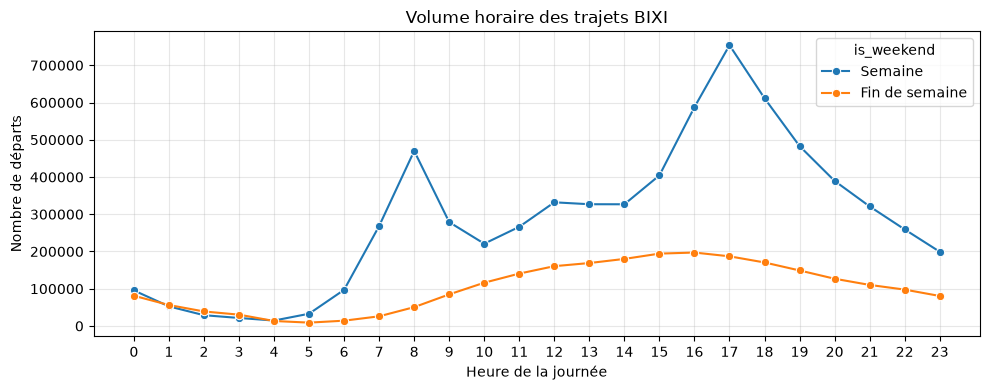

/opt/spark/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/tmp/ipykernel_14277/3640266119.py:24: FutureWarning:                           

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_stations_pd, y="STARTSTATIONNAME", x="count", palette="viridis")


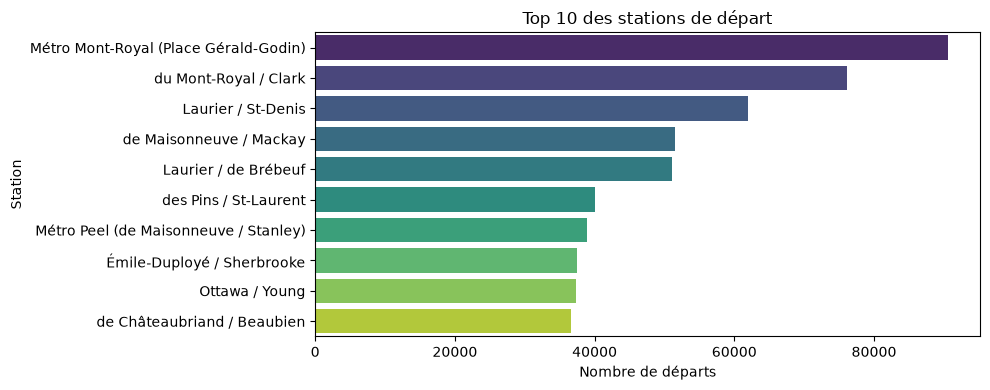

In [9]:
df_eda = df_clean \
    .withColumn("hour", F.hour("start_ts")) \
    .withColumn("day_of_week", F.dayofweek("start_ts")) \
    .withColumn("is_weekend", F.when(F.col("day_of_week").isin(1, 7), "Fin de semaine").otherwise("Semaine"))

# 1. Demande horaire (Semaine vs Fin de semaine)
hourly_pd = df_eda.groupBy("hour", "is_weekend").count().orderBy("hour").toPandas()

plt.figure(figsize=(10, 4))
sns.lineplot(data=hourly_pd, x="hour", y="count", hue="is_weekend", marker="o")
plt.title("Volume horaire des trajets BIXI")
plt.xlabel("Heure de la journée")
plt.ylabel("Nombre de départs")
plt.xticks(range(0, 24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 2. Top 10 des stations de départ
top_stations_pd = df_eda.groupBy("STARTSTATIONNAME").count() \
    .orderBy(F.desc("count")).limit(10).toPandas()

plt.figure(figsize=(10, 4))
sns.barplot(data=top_stations_pd, y="STARTSTATIONNAME", x="count", palette="viridis")
plt.title("Top 10 des stations de départ")
plt.xlabel("Nombre de départs")
plt.ylabel("Station")
plt.tight_layout()
plt.show()

### 4.2 Distribution de la durée des trajets et matrice de corrélation

Nous extrayons un petit échantillon aléatoire (limité à 5 000 trajets) converti en DataFrame Pandas afin de :
- Visualiser la distribution des durées des trajets de 60 minutes ou moins (la grande majorité des déplacements BIXI étant de courte durée).
- Examiner les corrélations linéaires entre la durée, l'heure, le jour de la semaine et les coordonnées géographiques.

/opt/spark/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


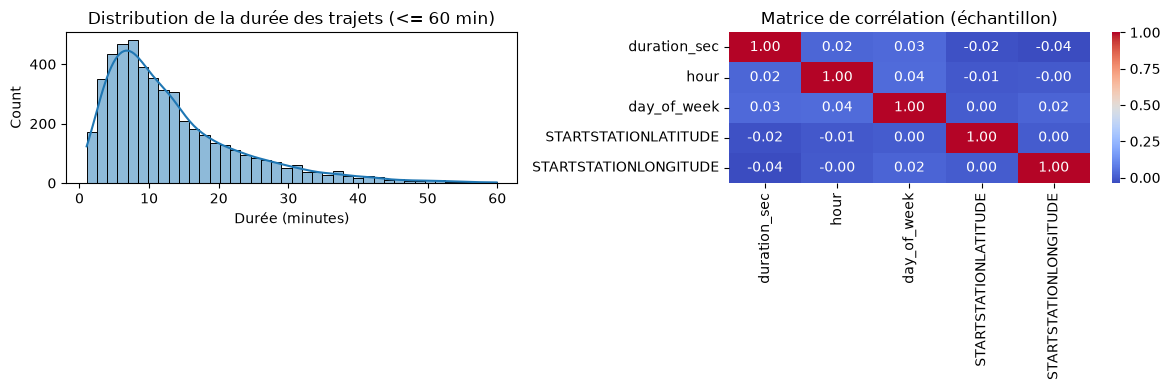

In [10]:
# 3. Distribution de la durée des trajets (échantillon)
sample_pd = df_eda.select("duration_sec", "hour", "day_of_week", "STARTSTATIONLATITUDE", "STARTSTATIONLONGITUDE") \
    .sample(withReplacement=False, fraction=0.01, seed=42).limit(5000).toPandas()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(sample_pd[sample_pd["duration_sec"] <= 3600]["duration_sec"] / 60, bins=40, kde=True, ax=axes[0])
axes[0].set_title("Distribution de la durée des trajets (<= 60 min)")
axes[0].set_xlabel("Durée (minutes)")

sns.heatmap(sample_pd.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", ax=axes[1])
axes[1].set_title("Matrice de corrélation (échantillon)")
plt.tight_layout()
plt.show()

### 4.3 Comparaison de l'utilisation de BIXI en fonction des précipitations

Pour évaluer l'effet de la pluie sans biais de couverture temporelle, nous restreignons les trajets à la période couverte par les capteurs pluviométriques (`hour_ts <= max_rain_ts`), joignons les données horaires de pluie et classons chaque heure en quatre niveaux d'intensité (aucune pluie, légère, modérée, forte). Nous comparons ensuite le nombre moyen de trajets par heure et la durée moyenne selon la météo et l'heure de la journée.

/opt/spark/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/opt/spark/python/pyspark/sql/pandas/types.py:778: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


                             nb_heures  trajets_moy_heure  duree_moy_min
rain_category                                                           
1. Aucune pluie (0 mm)            3071            1223.25          15.06
2. Pluie légère (<= 1 mm/h)        839             363.68          15.04
3. Pluie modérée (1-5 mm/h)        232            1504.45          13.87
4. Pluie forte (> 5 mm/h)          142            1549.95          13.40


/tmp/ipykernel_14277/2073438166.py:45: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=hourly_rain_pd, x="rain_category", y="trips_per_hour", order=order_cats, palette="Blues_d", ax=axes[1])


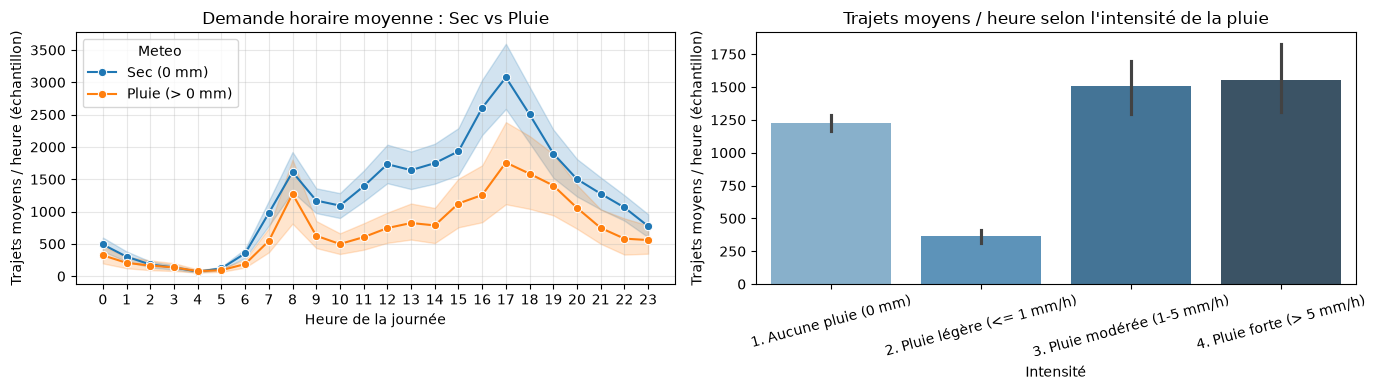

In [11]:
# 4. Comparaison de l'utilisation BIXI en fonction de la pluie
max_rain_ts = df_rain_hourly.agg(F.max("hour_ts")).collect()[0][0]

df_trips_rain = df_clean \
    .withColumn("hour_ts", F.date_trunc("hour", "start_ts")) \
    .filter(F.col("hour_ts") <= F.lit(max_rain_ts)) \
    .join(df_rain_hourly, on="hour_ts", how="left") \
    .na.fill({"rain_mm": 0.0, "is_raining": 0}) \
    .withColumn("hour", F.hour("hour_ts")) \
    .withColumn(
        "rain_category",
        F.when(F.col("rain_mm") == 0, "1. Aucune pluie (0 mm)")
         .when(F.col("rain_mm") <= 1.0, "2. Pluie légère (<= 1 mm/h)")
         .when(F.col("rain_mm") <= 5.0, "3. Pluie modérée (1-5 mm/h)")
         .otherwise("4. Pluie forte (> 5 mm/h)")
    )

# Agrégation par heure exacte pour comparer la moyenne de trajets/heure (sec vs pluie)
hourly_rain_pd = df_trips_rain \
    .groupBy("hour_ts", "hour", "is_raining", "rain_category") \
    .agg(
        F.count("*").alias("trips_per_hour"),
        F.avg(F.col("duration_sec") / 60.0).alias("avg_duration_min")
    ).toPandas()

hourly_rain_pd["Meteo"] = hourly_rain_pd["is_raining"].map({0: "Sec (0 mm)", 1: "Pluie (> 0 mm)"})

summary_rain = hourly_rain_pd.groupby("rain_category").agg(
    nb_heures=("hour_ts", "count"),
    trajets_moy_heure=("trips_per_hour", "mean"),
    duree_moy_min=("avg_duration_min", "mean")
).round(2)
print(summary_rain)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.lineplot(data=hourly_rain_pd, x="hour", y="trips_per_hour", hue="Meteo", marker="o", ax=axes[0])
axes[0].set_title("Demande horaire moyenne : Sec vs Pluie")
axes[0].set_xlabel("Heure de la journée")
axes[0].set_ylabel("Trajets moyens / heure (échantillon)")
axes[0].set_xticks(range(0, 24))
axes[0].grid(alpha=0.3)

order_cats = sorted(hourly_rain_pd["rain_category"].unique())
sns.barplot(data=hourly_rain_pd, x="rain_category", y="trips_per_hour", order=order_cats, palette="Blues_d", ax=axes[1])
axes[1].set_title("Trajets moyens / heure selon l'intensité de la pluie")
axes[1].set_xlabel("Intensité")
axes[1].set_ylabel("Trajets moyens / heure (échantillon)")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

### 4.4 Synthèse des observations de l'EDA

- **Saisonnalité journalière marquée** : en semaine, la demande présente deux pics nets aux heures de pointe (matin et fin d'après-midi), alors qu'elle suit une courbe en cloche centrée sur l'après-midi la fin de semaine.
- **Concentration spatiale** : un nombre restreint de stations centrales (Plateau-Mont-Royal, Ville-Marie) génère une part importante du volume total, justifiant l'inclusion de la station et de l'arrondissement comme variables explicatives.
- **Durées courtes et asymétriques** : la distribution des durées est fortement asymétrique à droite, concentrée autour de 10 à 15 minutes.
- **Effet de la météo** : les précipitations influencent le profil horaire de la demande ; les écarts par catégorie d'intensité reflètent également des effets confondants (heure de la journée et saison, les averses modérées/fortes survenant surtout aux mois chauds et en journée), ce qui confirme l'intérêt de combiner météo et variables temporelles dans le modèle.

## 5. Sélection des caractéristiques et ingénierie

### 5.1 Agrégation horaire par station, jointure météo et calcul des cibles

Pour passer du niveau « trajet individuel » au niveau « demande horaire par station », nous :
- Agrégeons les départs par `(station_name, arrondissement, hour_ts)` pour calculer `departures`, la durée moyenne (`avg_duration_sec`) et conserver les coordonnées GPS de la station.
- Agrégeons les arrivées par `(station_name, hour_ts)` pour obtenir `arrivals`.
- Effectuons la jointure avec la pluviométrie horaire (`rain_mm`, `is_raining`), remplaçons les absences d'arrivées ou de pluie par `0`, et calculons le flux net (`net_flow = arrivals - departures`), qui mesure directement le déficit ou le surplus horaire d'une station.

In [12]:
# Aligner la période sur la couverture des données de pluviométrie
max_rain_ts = df_rain_hourly.agg(F.max("hour_ts")).collect()[0][0]

# Agrégation horaire des départs par station
departures = df_clean \
    .withColumn("hour_ts", F.date_trunc("hour", "start_ts")) \
    .filter(F.col("hour_ts") <= F.lit(max_rain_ts)) \
    .groupBy(
        F.col("STARTSTATIONNAME").alias("station_name"),
        F.col("STARTSTATIONARRONDISSEMENT").alias("arrondissement"),
        "hour_ts"
    ).agg(
        F.count("*").alias("departures"),
        F.avg("duration_sec").alias("avg_duration_sec"),
        F.first("STARTSTATIONLATITUDE").alias("latitude"),
        F.first("STARTSTATIONLONGITUDE").alias("longitude")
    )

# Agrégation horaire des arrivées par station
arrivals = df_clean \
    .withColumn("hour_ts", F.date_trunc("hour", "end_ts")) \
    .filter(F.col("hour_ts") <= F.lit(max_rain_ts)) \
    .groupBy(F.col("ENDSTATIONNAME").alias("station_name"), "hour_ts") \
    .agg(F.count("*").alias("arrivals"))

# Jointure départs + arrivées + pluviométrie horaire et calcul du flux net
df_hourly = departures.join(arrivals, on=["station_name", "hour_ts"], how="left") \
    .join(df_rain_hourly.select("hour_ts", "rain_mm", "is_raining"), on="hour_ts", how="left") \
    .na.fill({"arrivals": 0, "rain_mm": 0.0, "is_raining": 0}) \
    .withColumn("net_flow", F.col("arrivals") - F.col("departures"))

### 5.2 Variables temporelles et variables décalées (*lags*)

Nous enrichissons chaque observation horaire avec :
- Des **variables calendaires** (`hour`, `day_of_week`, `month`, `is_weekend`) pour capturer les cycles horaires, hebdomadaires et saisonniers.
- Des **variables décalées (*lags*)** calculées via une fonction de fenêtre (`Window`) partitionnée par station et ordonnée chronologiquement (`lag_1h_departures`, `lag_1h_arrivals`, `lag_24h_departures`, `lag_1h_avg_duration_sec`), afin de fournir au modèle l'historique récent de demande à la station. Les valeurs manquantes en début de série sont imputées à `0`.

In [13]:
# Variables temporelles
df_hourly = df_hourly \
    .withColumn("hour", F.hour("hour_ts")) \
    .withColumn("day_of_week", F.dayofweek("hour_ts")) \
    .withColumn("month", F.month("hour_ts")) \
    .withColumn("is_weekend", F.when(F.col("day_of_week").isin(1, 7), 1).otherwise(0))

# Variables décalées (lag 1h et 24h par station)
w_station = Window.partitionBy("station_name").orderBy("hour_ts")

df_hourly = df_hourly \
    .withColumn("lag_1h_departures", F.lag("departures", 1).over(w_station)) \
    .withColumn("lag_1h_arrivals", F.lag("arrivals", 1).over(w_station)) \
    .withColumn("lag_24h_departures", F.lag("departures", 24).over(w_station)) \
    .withColumn("lag_1h_avg_duration_sec", F.lag("avg_duration_sec", 1).over(w_station)) \
    .na.fill({
        "lag_1h_departures": 0,
        "lag_1h_arrivals": 0,
        "lag_24h_departures": 0,
        "lag_1h_avg_duration_sec": 0.0
    })

# Persistance de df_hourly (RAM + disque) avant les StringIndexer.fit() et la sauvegarde Parquet
from pyspark import StorageLevel
df_hourly = df_hourly.persist(StorageLevel.MEMORY_AND_DISK)
print(f"Lignes horaires préparées : {df_hourly.count():,}")
df_clean.unpersist()

Lignes horaires préparées : 1,199,068


DataFrame[STARTSTATIONNAME: string, STARTSTATIONARRONDISSEMENT: string, STARTSTATIONLATITUDE: double, STARTSTATIONLONGITUDE: double, ENDSTATIONNAME: string, ENDSTATIONARRONDISSEMENT: string, ENDSTATIONLATITUDE: double, ENDSTATIONLONGITUDE: double, STARTTIMEMS: bigint, ENDTIMEMS: bigint, start_ts: timestamp, end_ts: timestamp, duration_sec: bigint]

### 5.3 Encodage des variables catégorielles et assemblage du vecteur `features`

Les algorithmes de Spark MLlib nécessitent des entrées numériques regroupées dans une colonne vecteur unique :
1. Nous encodons les colonnes catégorielles `station_name` et `arrondissement` en indices numériques (`station_idx`, `arrondissement_idx`) à l'aide de `StringIndexer` (`handleInvalid="keep"` pour gérer d'éventuelles nouvelles modalités).
2. Nous assemblons l'ensemble des 14 variables explicatives sélectionnées (identifiants encodés, coordonnées, attributs temporels, météo et lags (dont la durée moyenne décalée d'1h pour éviter toute fuite de données)) dans la colonne `features` avec `VectorAssembler` pour produire le DataFrame final `df_features`.

In [14]:
# Encodage des variables catégorielles
station_indexer = StringIndexer(inputCol="station_name", outputCol="station_idx", handleInvalid="keep")
arr_indexer = StringIndexer(inputCol="arrondissement", outputCol="arrondissement_idx", handleInvalid="keep")

df_indexed = station_indexer.fit(df_hourly).transform(df_hourly)
df_indexed = arr_indexer.fit(df_indexed).transform(df_indexed)

# Assemblage du vecteur de caractéristiques
feature_cols = [
    "station_idx", "arrondissement_idx",
    "latitude", "longitude",
    "hour", "day_of_week", "month", "is_weekend",
    "lag_1h_avg_duration_sec",
    "rain_mm", "is_raining",
    "lag_1h_departures", "lag_1h_arrivals", "lag_24h_departures"
]

assembler = VectorAssembler(inputCols=feature_cols, outputCol="features", handleInvalid="skip")
df_features = assembler.transform(df_indexed)

df_features.select("station_name", "hour_ts", "departures", "arrivals", "net_flow", "features").show(5, truncate=False)

26/11/20 15:05:41 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


+----------------------+-------------------+----------+--------+--------+-------------------------------------------------------------------------------------------+
|station_name          |hour_ts            |departures|arrivals|net_flow|features                                                                                   |
+----------------------+-------------------+----------+--------+--------+-------------------------------------------------------------------------------------------+
|16e avenue / St-Joseph|2026-03-31 15:00:00|1         |0       |-1      |(14,[0,1,2,3,4,5,6],[483.0,2.0,45.55293611277267,-73.56577143073082,15.0,3.0,3.0])         |
|16e avenue / St-Joseph|2026-04-01 06:00:00|1         |0       |-1      |[483.0,2.0,45.55293611277267,-73.56577143073082,6.0,4.0,4.0,0.0,283.0,0.0,0.0,1.0,0.0,0.0] |
|16e avenue / St-Joseph|2026-04-01 07:00:00|1         |0       |-1      |[483.0,2.0,45.55293611277267,-73.56577143073082,7.0,4.0,4.0,0.0,386.0,0.2,1.0,1.0,0.0,0.0] |
|16e

## 6. Sauvegarde des données préparées

Nous sauvegardons le DataFrame final `df_features` au format Parquet afin qu'il serve directement d'entrée à la phase suivante. Nous relisons ensuite le fichier Parquet sauvegardé pour vérifier le nombre de lignes, le nombre de colonnes et le schéma final.

In [15]:
# Sauvegarde locale en Parquet
df_features.write.mode("overwrite").parquet(OUTPUT_PARQUET_PATH)

# Sauvegarde HDFS
df_features.write.mode("overwrite").parquet(HDFS_OUTPUT_PARQUET_PATH)

# Vérification
df_check = spark.read.parquet(OUTPUT_PARQUET_PATH)
print(f"Parquet sauvegardé : {df_check.count():,} lignes, {len(df_check.columns)} colonnes")
df_check.printSchema()

Parquet sauvegardé : 1,199,068 lignes, 22 colonnes
root
 |-- hour_ts: timestamp (nullable = true)
 |-- station_name: string (nullable = true)
 |-- arrondissement: string (nullable = true)
 |-- departures: long (nullable = true)
 |-- avg_duration_sec: double (nullable = true)
 |-- latitude: double (nullable = true)
 |-- longitude: double (nullable = true)
 |-- arrivals: long (nullable = true)
 |-- rain_mm: double (nullable = true)
 |-- is_raining: integer (nullable = true)
 |-- net_flow: long (nullable = true)
 |-- hour: integer (nullable = true)
 |-- day_of_week: integer (nullable = true)
 |-- month: integer (nullable = true)
 |-- is_weekend: integer (nullable = true)
 |-- lag_1h_departures: long (nullable = true)
 |-- lag_1h_arrivals: long (nullable = true)
 |-- lag_24h_departures: long (nullable = true)
 |-- lag_1h_avg_duration_sec: double (nullable = true)
 |-- station_idx: double (nullable = true)
 |-- arrondissement_idx: double (nullable = true)
 |-- features: vector (nullable = t